
# Data Sources and Licenses

## Audio Data Source

프로젝트에서 사용한 모든 음성 파일은 모두 직접 녹음했습니다.

---

# Models Used

This project compares the performance of the following two ASR models:

## 1. Whisper Large-v3-turbo

* Model: `openai/whisper-large-v3-turbo`
* Type: 다국어 인식이 가능한 ASR모델

## 2. Korean Conformer CTC

* Model: `SungBeom/stt_kr_conformer_ctc_medium`
* Type: 한국어 음성 인식을 위해 학습된 Conformer CTC 기반 ASR모델


In [ ]:
!pip install -q openai-whisper jiwer librosa soundfile pandas openpyxl
!pip install -q "nemo_toolkit[asr]"

In [ ]:
import os
import re
import glob
import torch
import whisper
import pandas as pd
from jiwer import wer, cer, process_words
import glob
import nemo.collections.asr as nemo_asr
from transformers import pipeline

[NeMo W 2026-06-15 01:36:56 megatron_init:62] Megatron num_microbatches_calculator not found, using Apex version.
[NeMo W 2026-06-15 01:37:00 nemo_logging:364] /usr/local/lib/python3.12/dist-packages/pydub/utils.py:300: SyntaxWarning: invalid escape sequence '\('
      m = re.match('([su]([0-9]{1,2})p?) \(([0-9]{1,2}) bit\)$', token)
    
[NeMo W 2026-06-15 01:37:00 nemo_logging:364] /usr/local/lib/python3.12/dist-packages/pydub/utils.py:301: SyntaxWarning: invalid escape sequence '\('
      m2 = re.match('([su]([0-9]{1,2})p?)( \(default\))?$', token)
    
[NeMo W 2026-06-15 01:37:00 nemo_logging:364] /usr/local/lib/python3.12/dist-packages/pydub/utils.py:310: SyntaxWarning: invalid escape sequence '\('
      elif re.match('(flt)p?( \(default\))?$', token):
    
[NeMo W 2026-06-15 01:37:00 nemo_logging:364] /usr/local/lib/python3.12/dist-packages/pydub/utils.py:314: SyntaxWarning: invalid escape sequence '\('
      elif re.match('(dbl)p?( \(default\))?$', token):
    


In [ ]:
# 1. 파일 업로드
from google.colab import files
uploaded = files.upload()

Saving accent_1.wav to accent_1.wav
Saving accent_2.wav to accent_2.wav
Saving accent_3.wav to accent_3.wav
Saving accent_4.wav to accent_4.wav
Saving accent_5.wav to accent_5.wav
Saving accent_6.wav to accent_6.wav
Saving accent_7.wav to accent_7.wav
Saving accent_8.wav to accent_8.wav
Saving accent_9.wav to accent_9.wav
Saving accent_10.wav to accent_10.wav
Saving accent_11.wav to accent_11.wav
Saving accent_12.wav to accent_12.wav
Saving accent_13.wav to accent_13.wav
Saving accent_14.wav to accent_14.wav
Saving accent_15.wav to accent_15.wav
Saving fast_1.wav to fast_1.wav
Saving fast_2.wav to fast_2.wav
Saving fast_3.wav to fast_3.wav
Saving fast_4.wav to fast_4.wav
Saving fast_5.wav to fast_5.wav
Saving fast_6.wav to fast_6.wav
Saving fast_7.wav to fast_7.wav
Saving fast_8.wav to fast_8.wav
Saving fast_9.wav to fast_9.wav
Saving fast_10.wav to fast_10.wav
Saving fast_11.wav to fast_11.wav
Saving fast_12.wav to fast_12.wav
Saving fast_13.wav to fast_13.wav
Saving fast_14.wav to fa

In [ ]:
ref_df = pd.read_csv("references.csv", encoding="cp949")
ref_df["id"] = ref_df["id"].astype(int)

ref_dict = dict(zip(ref_df["id"], ref_df["text"]))

display(ref_df.head())
def extract_id(filename):
    base = os.path.basename(filename)

    # 파일명 안에 있는 숫자 찾기
    nums = re.findall(r"\d+", base)

    if len(nums) == 0:
        return None

    # 보통 normal_01.wav, accent_03.wav 이런 구조니까 마지막 숫자를 id로 사용
    return int(nums[-1])
def extract_category(filename):
    name = os.path.basename(filename).lower()

    # noise_normal 같은 파일명이 있으면 normal보다 noise가 먼저 잡혀야 함
    if "noise" in name:
        return "noise"
    elif "accent" in name:
        return "accent"
    elif "fast" in name:
        return "fast"
    elif "slow" in name:
        return "slow"
    elif "normal" in name:
        return "normal"
    else:
        return "unknown"

audio_files = glob.glob("*.wav")

data_rows = []

for f in audio_files:
    sid = extract_id(f)
    category = extract_category(f)

    if sid in ref_dict:
        data_rows.append({
            "filename": f,
            "id": sid,
            "category": category,
            "reference": ref_dict[sid]
        })

data_df = pd.DataFrame(data_rows).sort_values(["category", "id"])
display(data_df)



,id,text
0,1,집에서 돌아오는 택시 안에서 네가 쥐여준 편지를 읽었어
1,2,펜의 잉크가 다 떨어진 것 같았지
2,3,편지의 내용은 이기심에 관한 것이었다
3,4,나의 모든 마음을 알고 싶은 게 너의 이기심이라면
4,5,어떤 마음은 끝끝내 말할 수 없는 것이 나의 이기심이었으니까


,filename,id,category,reference
30,accent_1.wav,1,accent,집에서 돌아오는 택시 안에서 네가 쥐여준 편지를 읽었어
19,accent_2.wav,2,accent,펜의 잉크가 다 떨어진 것 같았지
57,accent_3.wav,3,accent,편지의 내용은 이기심에 관한 것이었다
53,accent_4.wav,4,accent,나의 모든 마음을 알고 싶은 게 너의 이기심이라면
2,accent_5.wav,5,accent,어떤 마음은 끝끝내 말할 수 없는 것이 나의 이기심이었으니까
...,...,...,...,...
61,slow_11.wav,11,slow,흐릿해져도 글자의 모양은 변하지 않으니까
38,slow_12.wav,12,slow,흐릿한 마음을 우리가 읽을 수 있다는 사실은 여전하니까
20,slow_13.wav,13,slow,사랑의 모양이 있다면 서로를 흐린 눈으로 바라보는 접힌 눈매의 모양일 거야
67,slow_14.wav,14,slow,착각 없이는 무엇도 사랑할 수 없으니까


In [ ]:
# Whisper
whisper_model = whisper.load_model("large-v3-turbo")

# SungBeom Conformer CTC Korean
conformer_model = nemo_asr.models.EncDecCTCModel.from_pretrained(
    model_name="SungBeom/stt_kr_conformer_ctc_medium"
)

def transcribe_whisper(filename):
    result = whisper_model.transcribe(
        filename,
        language="ko",
        fp16=torch.cuda.is_available()
    )
    return result["text"].strip()

def transcribe_conformer(filename):
    output = conformer_model.transcribe([filename])
    first = output[0]

    if isinstance(first, str):
        return first.strip()

    if hasattr(first, "text"):
        return first.text.strip()

    return str(first).strip()

100%|█████████████████████████████████████| 1.51G/1.51G [00:18<00:00, 86.8MiB/s]


stt_kr_conformer_ctc_medium.nemo:   0%|          | 0.00/491M [00:00<?, ?B/s]

[NeMo I 2026-06-15 01:45:47 mixins:184] Tokenizer SentencePieceTokenizer initialized with 2048 tokens


[NeMo W 2026-06-15 01:45:48 modelPT:188] If you intend to do training or fine-tuning, please call the ModelPT.setup_training_data() method and provide a valid configuration file to setup the train data loader.
    Train config : 
    manifest_filepath: /home/work/audrey3/dataset/train_manifest.json
    sample_rate: 16000
    batch_size: 16
    shuffle: true
    num_workers: 7
    pin_memory: true
    max_duration: 20.0
    min_duration: 0.1
    is_tarred: false
    tarred_audio_filepaths: null
    shuffle_n: 2048
    bucketing_strategy: synced_randomized
    bucketing_batch_size: null
    
[NeMo W 2026-06-15 01:45:48 modelPT:195] If you intend to do validation, please call the ModelPT.setup_validation_data() or ModelPT.setup_multiple_validation_data() method and provide a valid configuration file to setup the validation data loader(s). 
    Validation config : 
    manifest_filepath: /home/work/audrey3/dataset/test_manifest.json
    sample_rate: 16000
    batch_size: 16
    shuffle: fa

[NeMo I 2026-06-15 01:45:50 save_restore_connector:285] Model EncDecCTCModelBPE was successfully restored from /root/.cache/huggingface/hub/models--SungBeom--stt_kr_conformer_ctc_medium/snapshots/0e52cef4756b04b8a75762488574d63908d2da03/stt_kr_conformer_ctc_medium.nemo.


In [ ]:
models = {
    "whisper_large_v3_turbo": transcribe_whisper,
    "conformer_ctc_korean": transcribe_conformer
}

results = []


def normalize_text(text):
    text = str(text)
    text = re.sub(r"[.,!?…]", "", text)   # 문장부호 제거
    return text.strip()

for _, row in data_df.iterrows():
    filename = row["filename"]
    reference = row["reference"]
    sid = row["id"]
    category = row["category"]

    for model_name, transcribe_func in models.items():
        print("Running:", model_name, filename)

        try:
            prediction = transcribe_func(filename)
            error = ""
        except Exception as e:
            prediction = ""
            error = str(e)

        if prediction:
            ref_norm = normalize_text(reference)
            pred_norm = normalize_text(prediction)

            w = wer(ref_norm, pred_norm)
            c = cer(ref_norm, pred_norm)
            alignment = str(process_words(ref_norm, pred_norm).alignments)
        else:
            w = None
            c = None
            alignment = ""

        results.append({
            "model": model_name,
            "category": category,
            "id": sid,
            "filename": filename,
            "reference": reference,
            "prediction": prediction,
            "WER": w,
            "CER": c,
            "alignment": alignment,
            "error": error
        })

full_results = pd.DataFrame(results)


summary = (
    full_results
    .dropna(subset=["WER", "CER"])
    .groupby(["model", "category"])[["WER", "CER"]]
    .mean()
    .reset_index()
)
summary_pivot = summary.pivot(
    index="category",
    columns="model",
    values=["WER", "CER"]
)


Running: whisper_large_v3_turbo accent_1.wav


[NeMo W 2026-06-15 01:59:01 dataloader:826] The following configuration keys are ignored by Lhotse dataloader: use_start_end_token
[NeMo W 2026-06-15 01:59:01 dataloader:523] You are using a non-tarred dataset and requested tokenization during data sampling (pretokenize=True). This will cause the tokenization to happen in the main (GPU) process,possibly impacting the training speed if your tokenizer is very large.If the impact is noticable, set pretokenize=False in dataloader config.(note: that will disable token-per-second filtering and 2D bucketing features)


Running: conformer_ctc_korean accent_1.wav


Transcribing: 1it [00:00, 12.79it/s]

Running: whisper_large_v3_turbo accent_2.wav



[NeMo W 2026-06-15 01:59:02 dataloader:826] The following configuration keys are ignored by Lhotse dataloader: use_start_end_token
[NeMo W 2026-06-15 01:59:02 dataloader:523] You are using a non-tarred dataset and requested tokenization during data sampling (pretokenize=True). This will cause the tokenization to happen in the main (GPU) process,possibly impacting the training speed if your tokenizer is very large.If the impact is noticable, set pretokenize=False in dataloader config.(note: that will disable token-per-second filtering and 2D bucketing features)


... (290 outputs left out)

Running: whisper_large_v3_turbo slow_15.wav



[NeMo W 2026-06-15 01:59:45 dataloader:826] The following configuration keys are ignored by Lhotse dataloader: use_start_end_token
[NeMo W 2026-06-15 01:59:45 dataloader:523] You are using a non-tarred dataset and requested tokenization during data sampling (pretokenize=True). This will cause the tokenization to happen in the main (GPU) process,possibly impacting the training speed if your tokenizer is very large.If the impact is noticable, set pretokenize=False in dataloader config.(note: that will disable token-per-second filtering and 2D bucketing features)


Running: conformer_ctc_korean slow_15.wav


Transcribing: 1it [00:00, 18.87it/s]


In [ ]:
print("전체 결과")
display(full_results.head())
print("결과 요약")
display(summary)
print("비교용 요약 피벗 테이블")
display(summary_pivot)

전체 결과


,model,category,id,filename,reference,prediction,WER,CER,alignment,error
0,whisper_large_v3_turbo,accent,1,accent_1.wav,집에서 돌아오는 택시 안에서 네가 쥐여준 편지를 읽었어,집에서 돌아오는 택시 안에서 네가 지어준 편지를 읽었어.,0.125000,0.066667,"[[AlignmentChunk(type='equal', ref_start_idx=0...",
1,conformer_ctc_korean,accent,1,accent_1.wav,집에서 돌아오는 택시 안에서 네가 쥐여준 편지를 읽었어,집에서 돌아오는 택시 안에서 니가 지어준 편지를 읽었어,0.250000,0.100000,"[[AlignmentChunk(type='equal', ref_start_idx=0...",
2,whisper_large_v3_turbo,accent,2,accent_2.wav,펜의 잉크가 다 떨어진 것 같았지,펜에 잉크가 다 떨어진 것 같았지.,0.166667,0.055556,"[[AlignmentChunk(type='substitute', ref_start_...",
3,conformer_ctc_korean,accent,2,accent_2.wav,펜의 잉크가 다 떨어진 것 같았지,팬의 잉크가 다 떨어진 것 같았지,0.166667,0.055556,"[[AlignmentChunk(type='substitute', ref_start_...",
4,whisper_large_v3_turbo,accent,3,accent_3.wav,편지의 내용은 이기심에 관한 것이었다,편지의 내용은 이기심에 관한 것이었다.,0.000000,0.000000,"[[AlignmentChunk(type='equal', ref_start_idx=0...",


결과 요약


,model,category,WER,CER
0,conformer_ctc_korean,accent,0.048413,0.018878
1,conformer_ctc_korean,fast,0.121720,0.042009
2,conformer_ctc_korean,noise,0.165823,0.080452
3,conformer_ctc_korean,normal,0.084048,0.035672
4,conformer_ctc_korean,slow,0.058598,0.030951
5,whisper_large_v3_turbo,accent,0.028968,0.013481
6,whisper_large_v3_turbo,fast,0.062302,0.019151
7,whisper_large_v3_turbo,noise,0.159182,0.080962
8,whisper_large_v3_turbo,normal,0.038889,0.014295
9,whisper_large_v3_turbo,slow,0.065584,0.026652


비교용 요약 피벗 테이블


WER                                         CER  \
model    conformer_ctc_korean whisper_large_v3_turbo conformer_ctc_korean   
category                                                                    
accent               0.048413               0.028968             0.018878   
fast                 0.121720               0.062302             0.042009   
noise                0.165823               0.159182             0.080452   
normal               0.084048               0.038889             0.035672   
slow                 0.058598               0.065584             0.030951   

                                 
model    whisper_large_v3_turbo  
category                         
accent                 0.013481  
fast                   0.019151  
noise                  0.080962  
normal                 0.014295  
slow                   0.026652

# Model Comparison

 두 한국어 ASR모델을 Normal, Accent, Noise조건으로 실험하였다.
 Whisper는 전체적으로 더 낮은 오류율을 보였으며 전반적으로 안정적인 성능을 보였다. Whisper는 발음이 조금 불명확하더라도 문맥을 이용해 자연스러운 문장으로 복원하는 경향이 있었다. 다만 이 특성때문에 실제로 들린 소리를 그대로 받아쓰기보다는 발음이 비슷하고 문맥상 자연스럽다고 여기는 단어로 바꾸는 오류가 발생할 수 있다.
 Conformer는 한국어 특화 모델이기 때문에 더 좋은 성능을 기대했지만 실제 결과에서 대부부 기본 조건에서 Whisper보다 더 높은 오류율을 보였다. Conformer는 문맥을 이용한 보정보다는 들리는 발음을 더 직접적으로 받아쓰는 경향이 있었고 이 때문에 유사 발음 단어나 조사에서 오류가 반복적으로 나타났다.

## Error pattern

 전체 오류를 분석한 결과 두 모델 모두 무작위로 단어를 틀리기보다는 발음이 비슷한 단어, 조사, 축약 표현에서 오류가 자주 발생하였다.

### 자주 틀린 패턴

| Reference | Prediction | Count |
| --------- | ---------- | ----: |
| 마는        | 많은         |     8 |
| 그렇기에      | 그렇게        |     6 |
| 기어이       | 기여이        |     5 |
| 기분으로      | 기본으로       |     5 |
| 쥐여준       | 지어준        |     4 |
| 펜의        | 펜에         |     4 |

  랜덤으로 틀리는 것이 아니라 발음이 비슷한 단어, 조사, 축약표현을 많이 틀렸다.

### 자주 틀린 글자 단위

| Reference | Prediction | Count |
| --------- | ---------- | ----: |
| 여        | 어         |     9 |
| 마        | 많         |     8 |
| 는        | 은         |     8 |
| 쥐        | 지         |     7 |
| 의        | 예         |     7 |
| 어        | 여         |     5 |
| 분        | 본         |     5 |
| 네        | 니         |     4 |
| 펜        | 팬         |     4 |

 한국어에서 실제 발음이 흐려지거나 빠르게 말하면 잘 섞이는 글자 위주로 틀렸다..

## Comparison by Audio Condition

 Normal 조건에서는 Whisper의 WER이 0.0389, CER이 0.0143이었고 Conformer는 WER 0.0840, CER 0.0357로 나타났다. 일반적인 발화 조건에서는 Whisper가 Conformer보다 원문을 더 정확하게 인식하였다.
 Accent 조건에서도 Whisper가 더 좋은 성능을 보였다. Whisperdml WER은 0.029,CER은 0.0135였고 Conformer는 WER 0.0484,CER 0.0189였다. Accent변화가 Normal에 비해 성능 저하를 일으킬 것이라고 예상했던 것과 달리 accent변화는 두 모델 모두에게 큰 변화를 만들지 않았다. 이는 억양이나 음의 높낮이 변화보다 다른 조건이 ASR성능에 더 큰 영향을 줄 수 있음을 보여준다.
 Noise조건에서는 두 모델 모두 오류율이 크게 증가하였다. Conformer는 WER 0.1658, CER 0.0805였고 Whisper는 WER 0.1592, CER 0.0810이었다. WER기준으로는 Whisper가 아주 약간 낮았지만 CER기준으로는 거의 차이가 없었다. 따라서 noise 조건에서는 특정 모델의 우위가 크다기보다는 두 모델 모두 잡음에 의해 인식 성능이 크게 저하되었다고 볼 수 있다.



---
# Deep Dive
## 발화 속도 변화에 따른 ASR 안정성

 Deep dive에서는 발화 속도가 slow-> normal-> fast로 바뀔 때 Whisper와 Conformer의 WER/CER가 얼마나 안정적으로 유지되는지 실험하였다.

## Fast
  
  Fast조건에서는 두 모델의 차이가 크게 나타났다. Whisper의 WER은 0.0623 CER은 0.0192였고 Conformer의 WER은 0.1217,CER은 0.0420이었다. WER기준으로 Whisper가 Conformer보다 2배 낮은 오류율을 보였다. 빠른 발화에서는 초성, 중성, 종성의 경계가 흐려지고 단어 사이 구분도 약해지기 때문에 ASR 모델이 음절 단위를 안정적으로 분리하기 어려워진다. Conformer에서는 이러한 영향이 더 크게 나타났으며 '펜의'가 '텐의', '편지의'가 '현지의', '기분으로'가 '기본으로', '나의 이기심'이 '나의 애기심'으로 인식되는 오류가 발생하였다. 이는 문맥을 고려하지 않고 들리는 대로 출력하여서 발생하는 오류라고 해석하였다.

## Slow
   
  Slow조건에서는 Fast조건과는 다른 결과가 나타났다 Conformer의 WER은 0.0586, Whisper의 WER은 0.0656으로 WER 기준에서는 Conformer가 약간 더 낮은 오류율을 보였다. 그러나 CER기준에서는 Whisper가 0.0267, Conformer가 0.0310으로 Whisper가 조금 더 낮았다. 이러한 결과는 느린 발화 조건에서 두 모델의 차이가 크지 않고 단어 단위 오류율에서는 Conformer가 조금 유리했지만 글자 단위 오류율에서는 Whisper가 조금 더 안정적이었음을 보여준다.
  이 결과는 두 모델의 학습 방향 차이에서 비롯된 것으로 해석할 수 있다. Whisper는 대규모 다국어 음성 데이터로 학습되어 다양한 발화속도와 음성 환경을 경험했을 가능성이 높기 때문에 빠른 발화처럼 입력 조건이 어려워졌을때 더 높은 안정성을 보였다. 하지만 Conformer는 한국어에 특화된 모델이지만 빠른 발화에 대한 일반화 능력은 상대적으로 제한적이었을 수 있다. 다만 느린 발화에서는 한국어 음절과 단어 경계가 더 명확히 드러나기떄문에 Conformer가 일부 지표에서 더 안정적인 결과를 보였다.





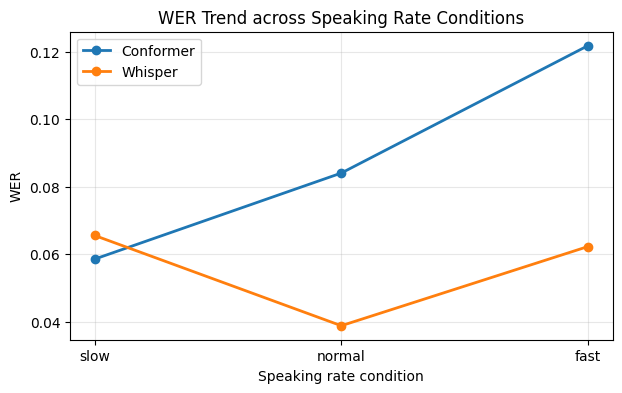

In [ ]:
#@title WER Trend { display-mode: "form" }



import pandas as pd

import matplotlib.pyplot as plt



data = [

    ["Conformer", "slow", 0.058598, 0.030951],

    ["Conformer", "normal", 0.084048, 0.035672],

    ["Conformer", "fast", 0.121720, 0.042009],

    ["Whisper", "slow", 0.065584, 0.026652],

    ["Whisper", "normal", 0.038889, 0.014295],

    ["Whisper", "fast", 0.062302, 0.019151],

]



df = pd.DataFrame(data, columns=["model", "condition", "WER", "CER"])



order = ["slow", "normal", "fast"]

df["condition"] = pd.Categorical(df["condition"], categories=order, ordered=True)

df = df.sort_values(["model", "condition"])



plt.figure(figsize=(7, 4))



for model in df["model"].unique():

    temp = df[df["model"] == model]

    plt.plot(temp["condition"], temp["WER"], marker="o", linewidth=2, label=model)



plt.title("WER Trend across Speaking Rate Conditions")

plt.xlabel("Speaking rate condition")

plt.ylabel("WER")

plt.grid(True, alpha=0.3)

plt.legend()

plt.show()

그래프를 보면 발화 속도 변화에 따라 두 모델의 오류율 변화 양상이 다르게 나타난다. WER 기준으로 Conformer는 slow 조건에서 0.0586으로 Whisper의 0.0656보다 약간 낮았지만 normal 조건에서는 0.0840, fast 조건에서는 0.1217까지 증가하였다. 반면 Whisper는 normal 조건에서 0.0389, fast 조건에서 0.0623을 기록하여 빠른 발화에서도 Conformer보다 낮은 오류율을 유지하였다. 따라서 WER trend를 기준으로 보면 Conformer는 느린 발화에서는 일부 강점을 보였지만 발화가 빨라질수록 오류율이 더 크게 증가하여 속도 변화에 대한 안정성은 Whisper가 더 높게 나타났다.


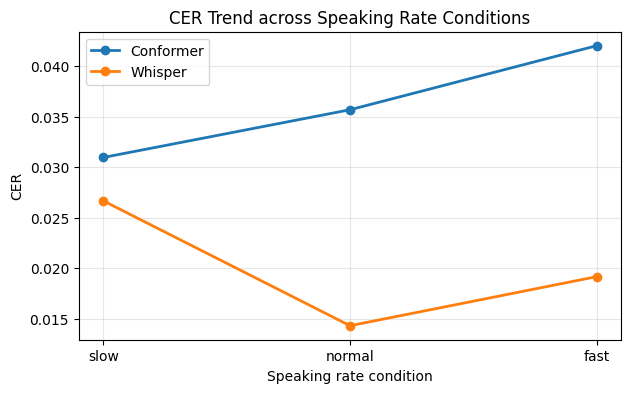

In [ ]:
#@title CER Trend { display-mode: "form" }



import pandas as pd

import matplotlib.pyplot as plt



data = [

    ["Conformer", "slow", 0.058598, 0.030951],

    ["Conformer", "normal", 0.084048, 0.035672],

    ["Conformer", "fast", 0.121720, 0.042009],

    ["Whisper", "slow", 0.065584, 0.026652],

    ["Whisper", "normal", 0.038889, 0.014295],

    ["Whisper", "fast", 0.062302, 0.019151],

]



df = pd.DataFrame(data, columns=["model", "condition", "WER", "CER"])



order = ["slow", "normal", "fast"]

df["condition"] = pd.Categorical(df["condition"], categories=order, ordered=True)

df = df.sort_values(["model", "condition"])



plt.figure(figsize=(7, 4))



for model in df["model"].unique():

    temp = df[df["model"] == model]

    plt.plot(temp["condition"], temp["CER"], marker="o", linewidth=2, label=model)



plt.title("CER Trend across Speaking Rate Conditions")

plt.xlabel("Speaking rate condition")

plt.ylabel("CER")

plt.grid(True, alpha=0.3)

plt.legend()

plt.show()

CER 기준에서는 Whisper가 slow, normal, fast 모든 속도 조건에서 Conformer보다 낮은 오류율을 보였다. Fast 조건에서 Whisper의 CER은 0.0192였고 Conformer의 CER은 0.0420으로 빠른 발화에서 글자 단위 오류 차이가 크게 나타났다. Slow 조건에서는 WER 기준으로 Conformer가 약간 더 좋았지만 CER 기준에서는 Whisper가 더 낮은 오류율을 보여 글자 단위 인식 안정성은 Whisper가 더 높았다고 해석할 수 있다.

따라서 WER에서는 slow 조건에서 Conformer가 일부 강점을 보였지만 CER까지 함께 고려하면 Whisper가 글자 단위 인식에서 더 안정적인 모델로 나타났다.

## Conclusion

 발화 속도는 ASR에서 중요한 요소다. 빠르게 말하면 단어와 단어사이 경계가 흐려지기 때문이다. 따라서 slow,normal,fast 조건에서 WER/CER을 비교해서 모델이 속도 변화에 얼마나 강한지 모델의 안정성을 정량적으로 분석하였다.
 결론적으로는 Whisper가 속도 변화에 대한 전반적인 안정성이 더 높고 Conformer는 느리고 명확한 한국어 발화에서 일부 강점을 보였다고 해석할 수 있다.
`